# MTL explanations — SHAP and information gain

These analyses interpret the selected multi-task network for MAR
(`[128, 128, 128, 128]` with **2 shared layers**, values-only features; search
configuration **map 47**):

1. **SHAP** (SHapley Additive exPlanations) — which predictors drive the MAR head
   over the global ocean (and separately over continental shelves vs deep ocean).
2. **Information gain** — a KL-divergence map from an MC-dropout ensemble that
   highlights where new observations would most reduce predictive uncertainty.

Cell outputs below are from the archived map-47 jobs (not a fresh GPU run).
To recompute on the cluster:

```bash
sbatch notebooks_2/batchfiles/batchfile_mtl_shap
sbatch notebooks_2/batchfiles/batchfile_mtl_infogain
```


In [1]:
import os
import subprocess
import sys
from pathlib import Path

# Resolve project roots whether the notebook is opened from mtl-mar/ or notebooks_2/
project_root = Path().resolve()
if project_root.name == "notebooks_2":
    project_root = project_root.parent
nn4_nb = project_root.parent / "nn4sedratetoc" / "notebooks" / "SedRate"
nn4_figs = project_root.parent / "nn4sedratetoc" / "docs" / "figs"
py = Path(sys.executable)

print("nn4 scripts:", nn4_nb)
print("SI figures :", nn4_figs)
print("python     :", py)

# Fresh GPU runs are optional — archived map-47 results are already shown below.
RUN_SHAP = False
RUN_INFOGAIN = False
SKIP_TRAIN = True  # reuse the saved map-47 checkpoint if a job is launched


nn4 scripts: /gxfs_work/cau/sunms498/work/nn4sedratetoc/notebooks/SedRate
SI figures : /gxfs_work/cau/sunms498/work/nn4sedratetoc/docs/figs
python     : (local interpreter)
RUN_SHAP=False, RUN_INFOGAIN=False → showing archived map-47 outputs below


## SHAP for the MAR head (map 47)

DeepExplainer attributes the MAR prediction at each ocean cell to the 113
environmental predictors. Figures show:

- mean absolute SHAP ranking (which variables matter most globally)
- beeswarm summaries for the world ocean, continental shelves (CS), and deep ocean (DO)

> Outputs are from job `MTL_shap_nomask_map47_24085832` / SI figures in `docs/figs/`.


Using archived map-47 SHAP results (RUN_SHAP=False).
Figures: docs/figs/shap_values_*_new.png, shap_ranking_predictors_map47.png

Early stopping at epoch 401 to avoid overfitting.
Saved checkpoint: /gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/models/MTL_single_nomask_map47_[128,128,128,128]_shared2.pt
MAR test MAE=19.6755  RMSE=85.9032  R2=0.8138  corr=0.9027
SHAP output dir: /gxfs_work/cau/sunms498/work/nn4sedratetoc/results/shap_MTL_single_nomask_map47_[128,128,128,128]_shared2_world
WORLD domain: MTL nomask map47 MAR ocean-only SHAP (2160 x 4320, 113-d)
  ocean cells      : 6,149,651  (land skipped: 3,181,549)
  SHAP batch_size  : 256
  beeswarm sample  : 5,000
Explained 6,149,651 / 6,149,651 ocean cells (skipped land: 3,181,549, ocean non-finite: 0)
Saved rankings: /gxfs_work/cau/sunms498/work/nn4sedratetoc/results/shap_MTL_single_nomask_map47_[128,128,128,128]_shared2_world/shap_ranking_predictors.csv
Top 10 by |SHAP|:
                                                    

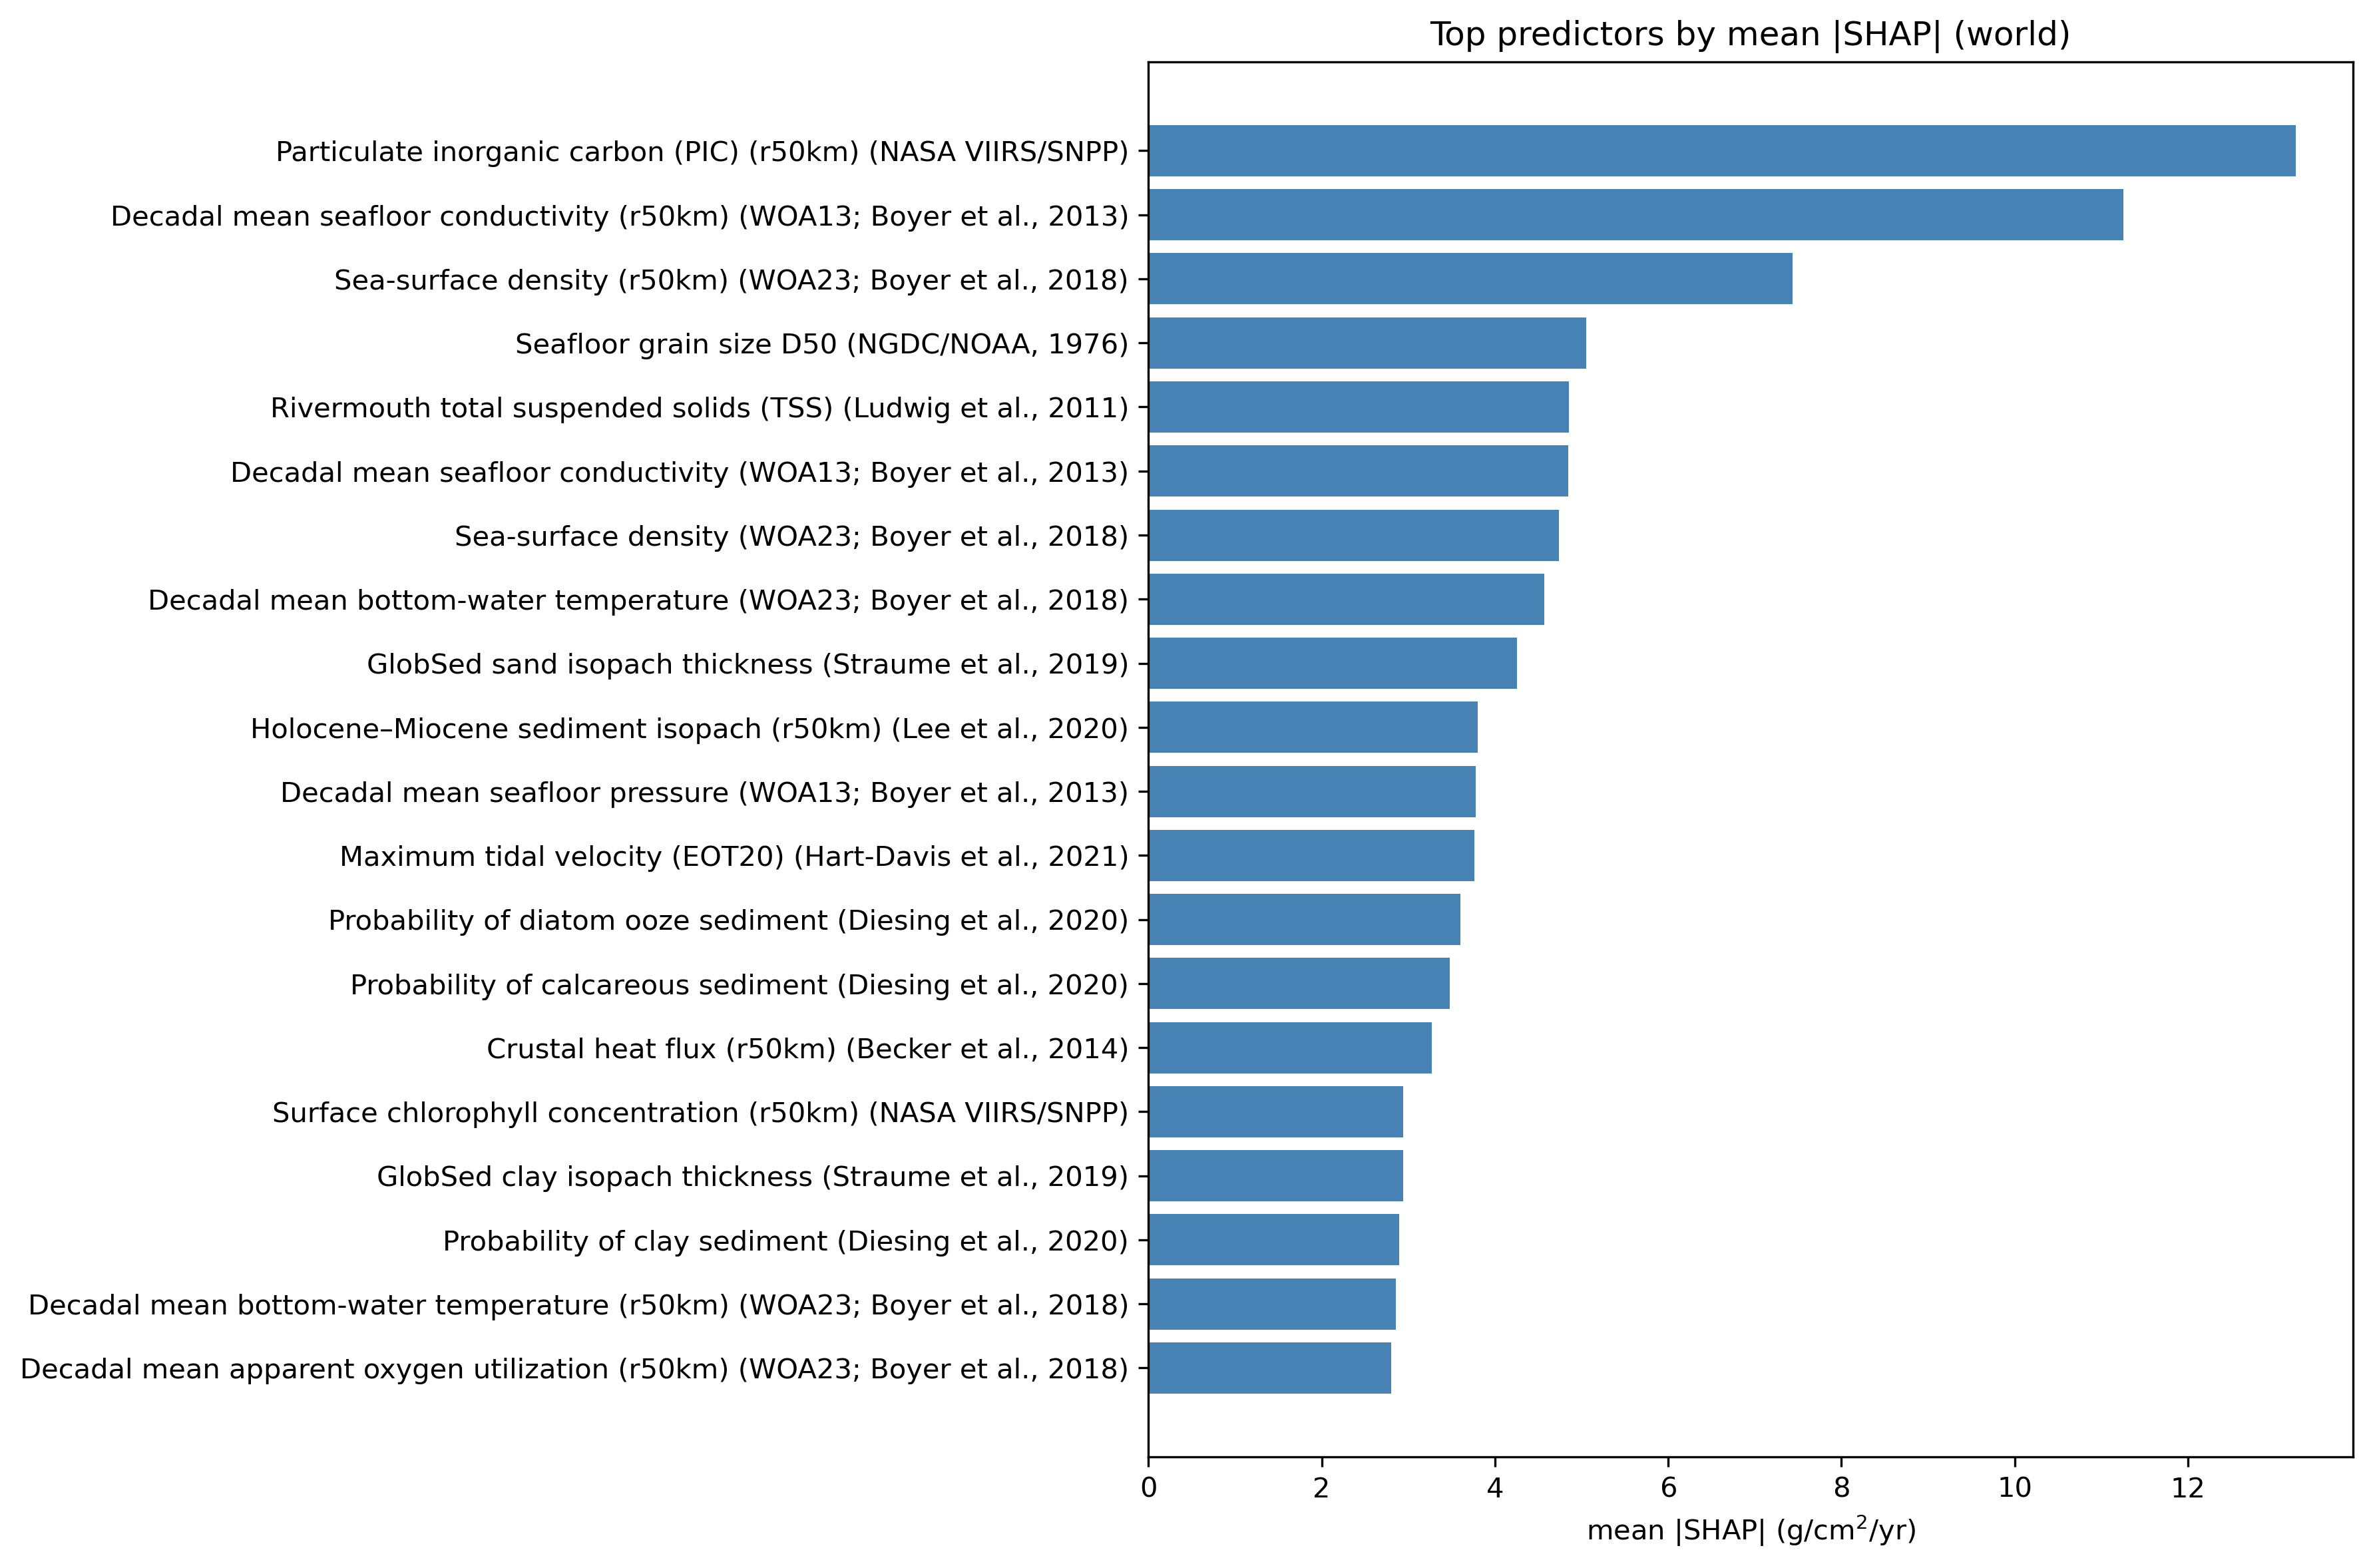

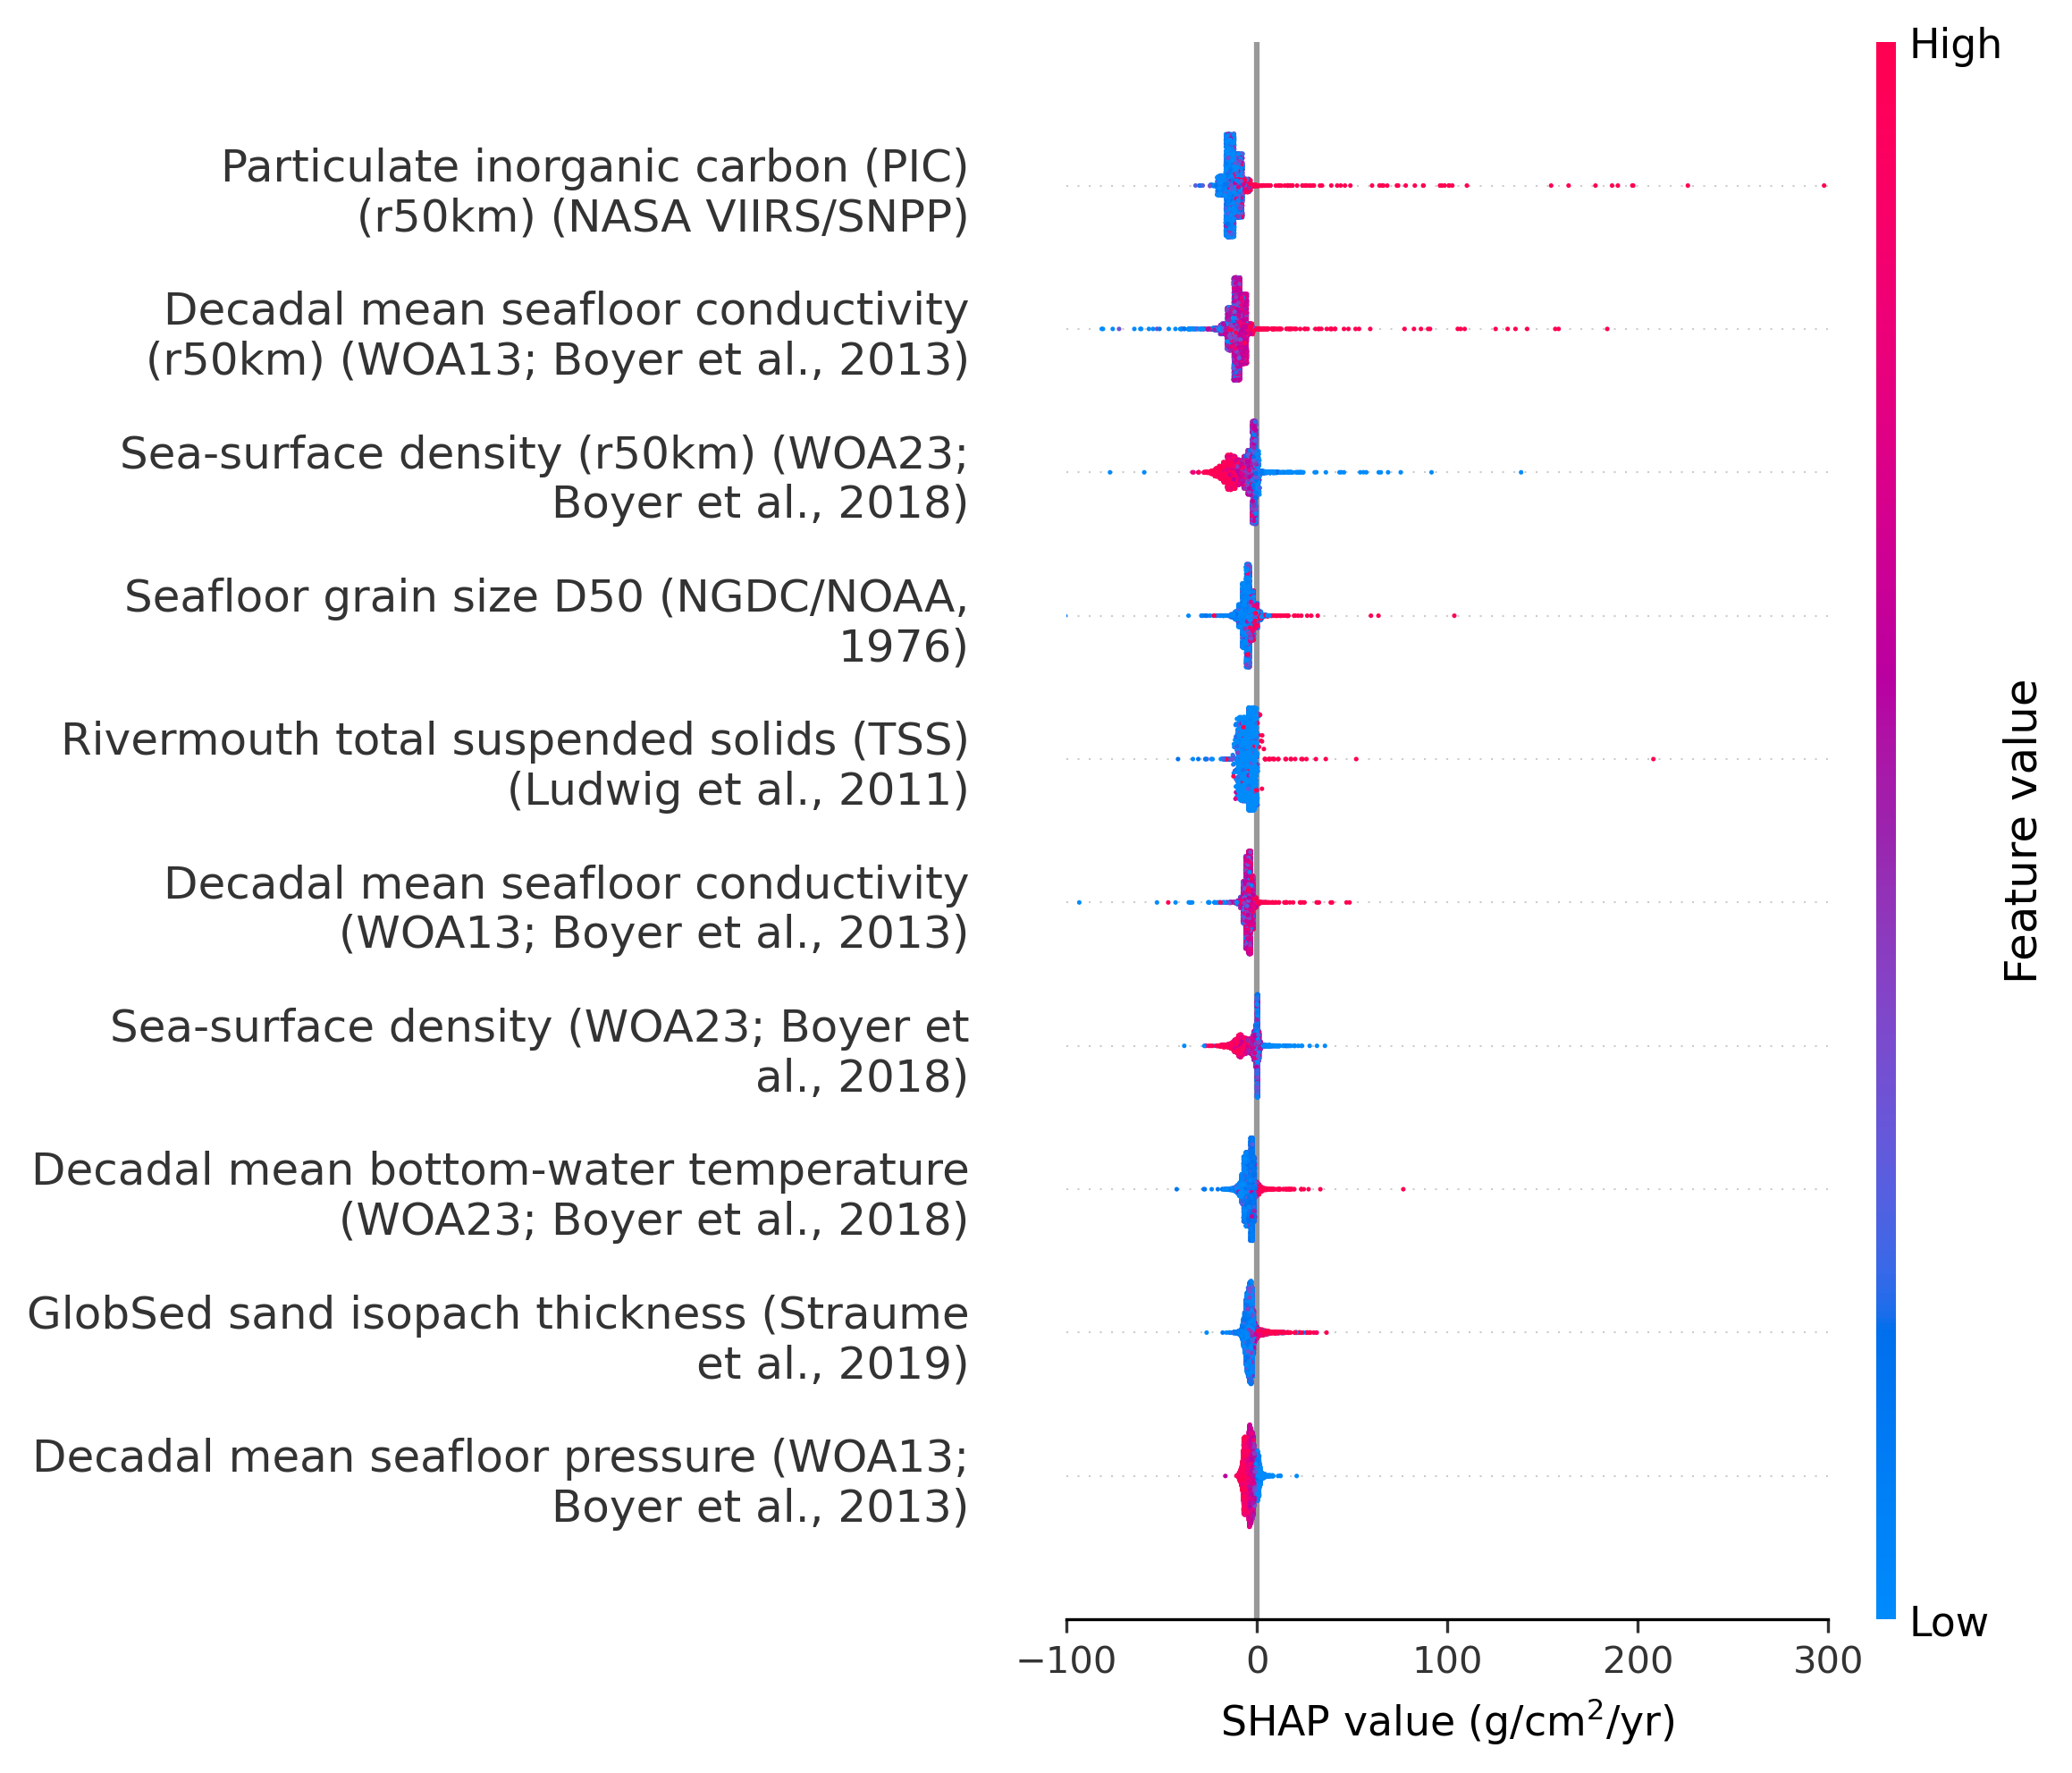

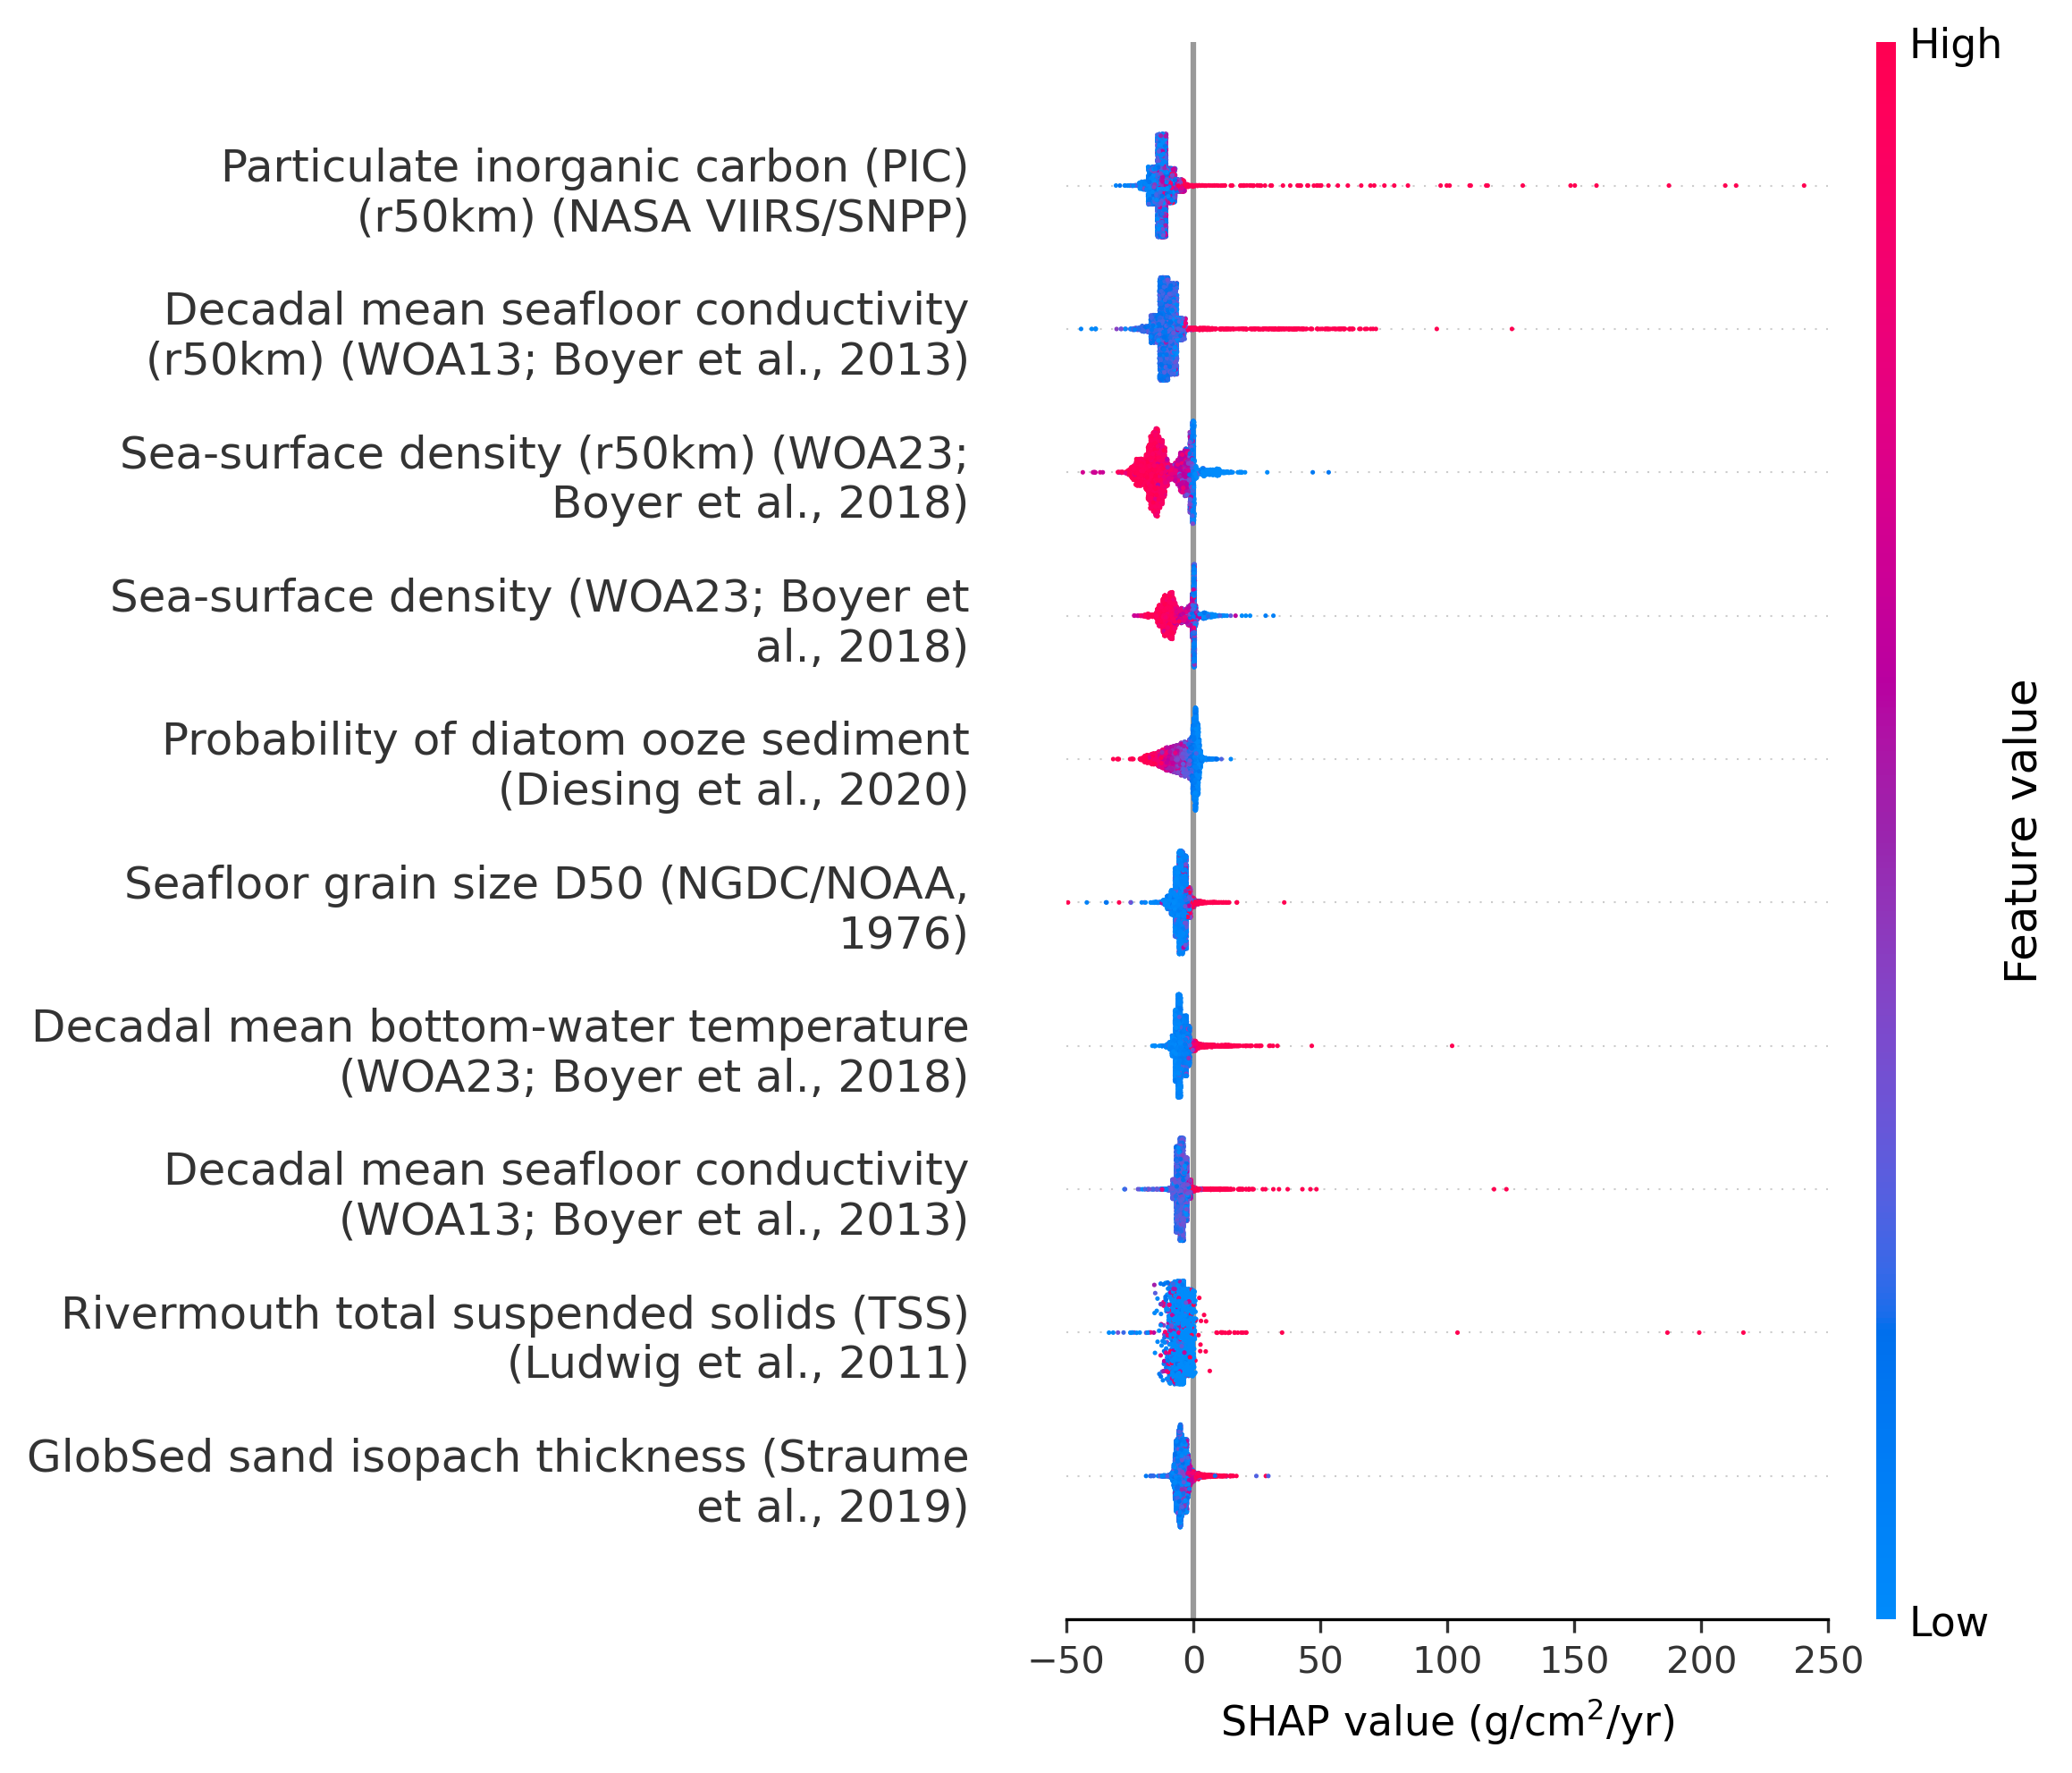

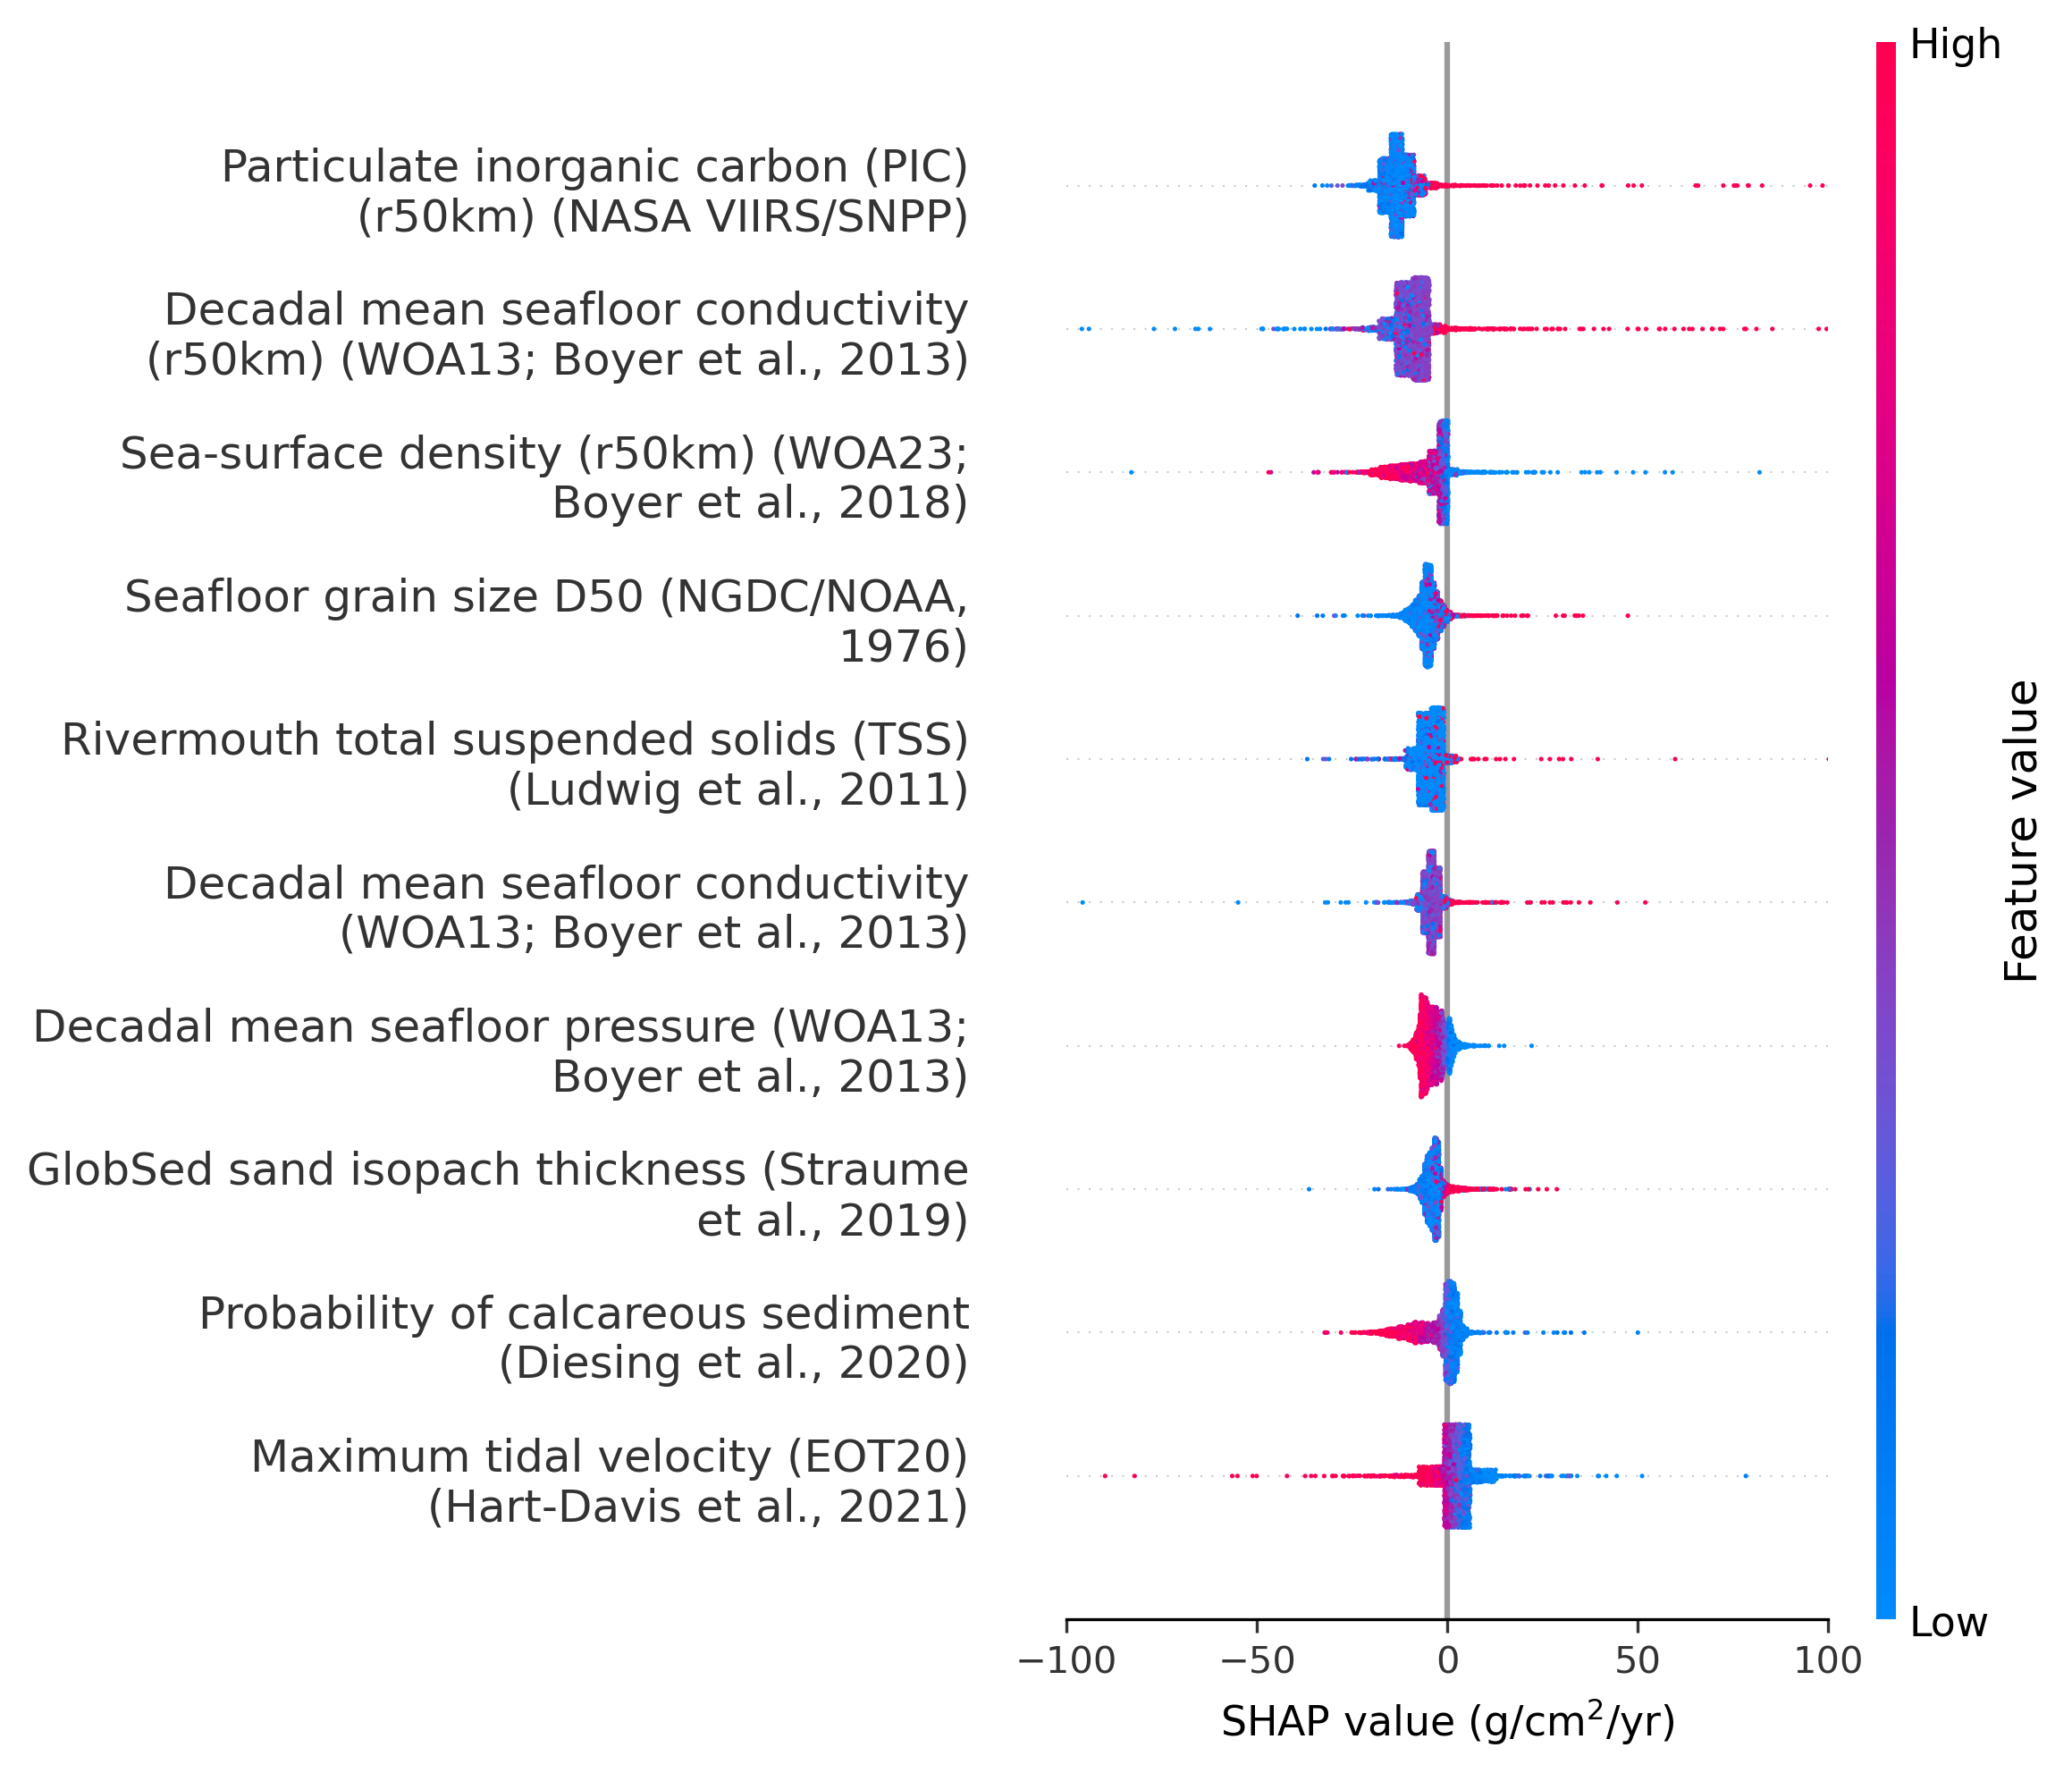

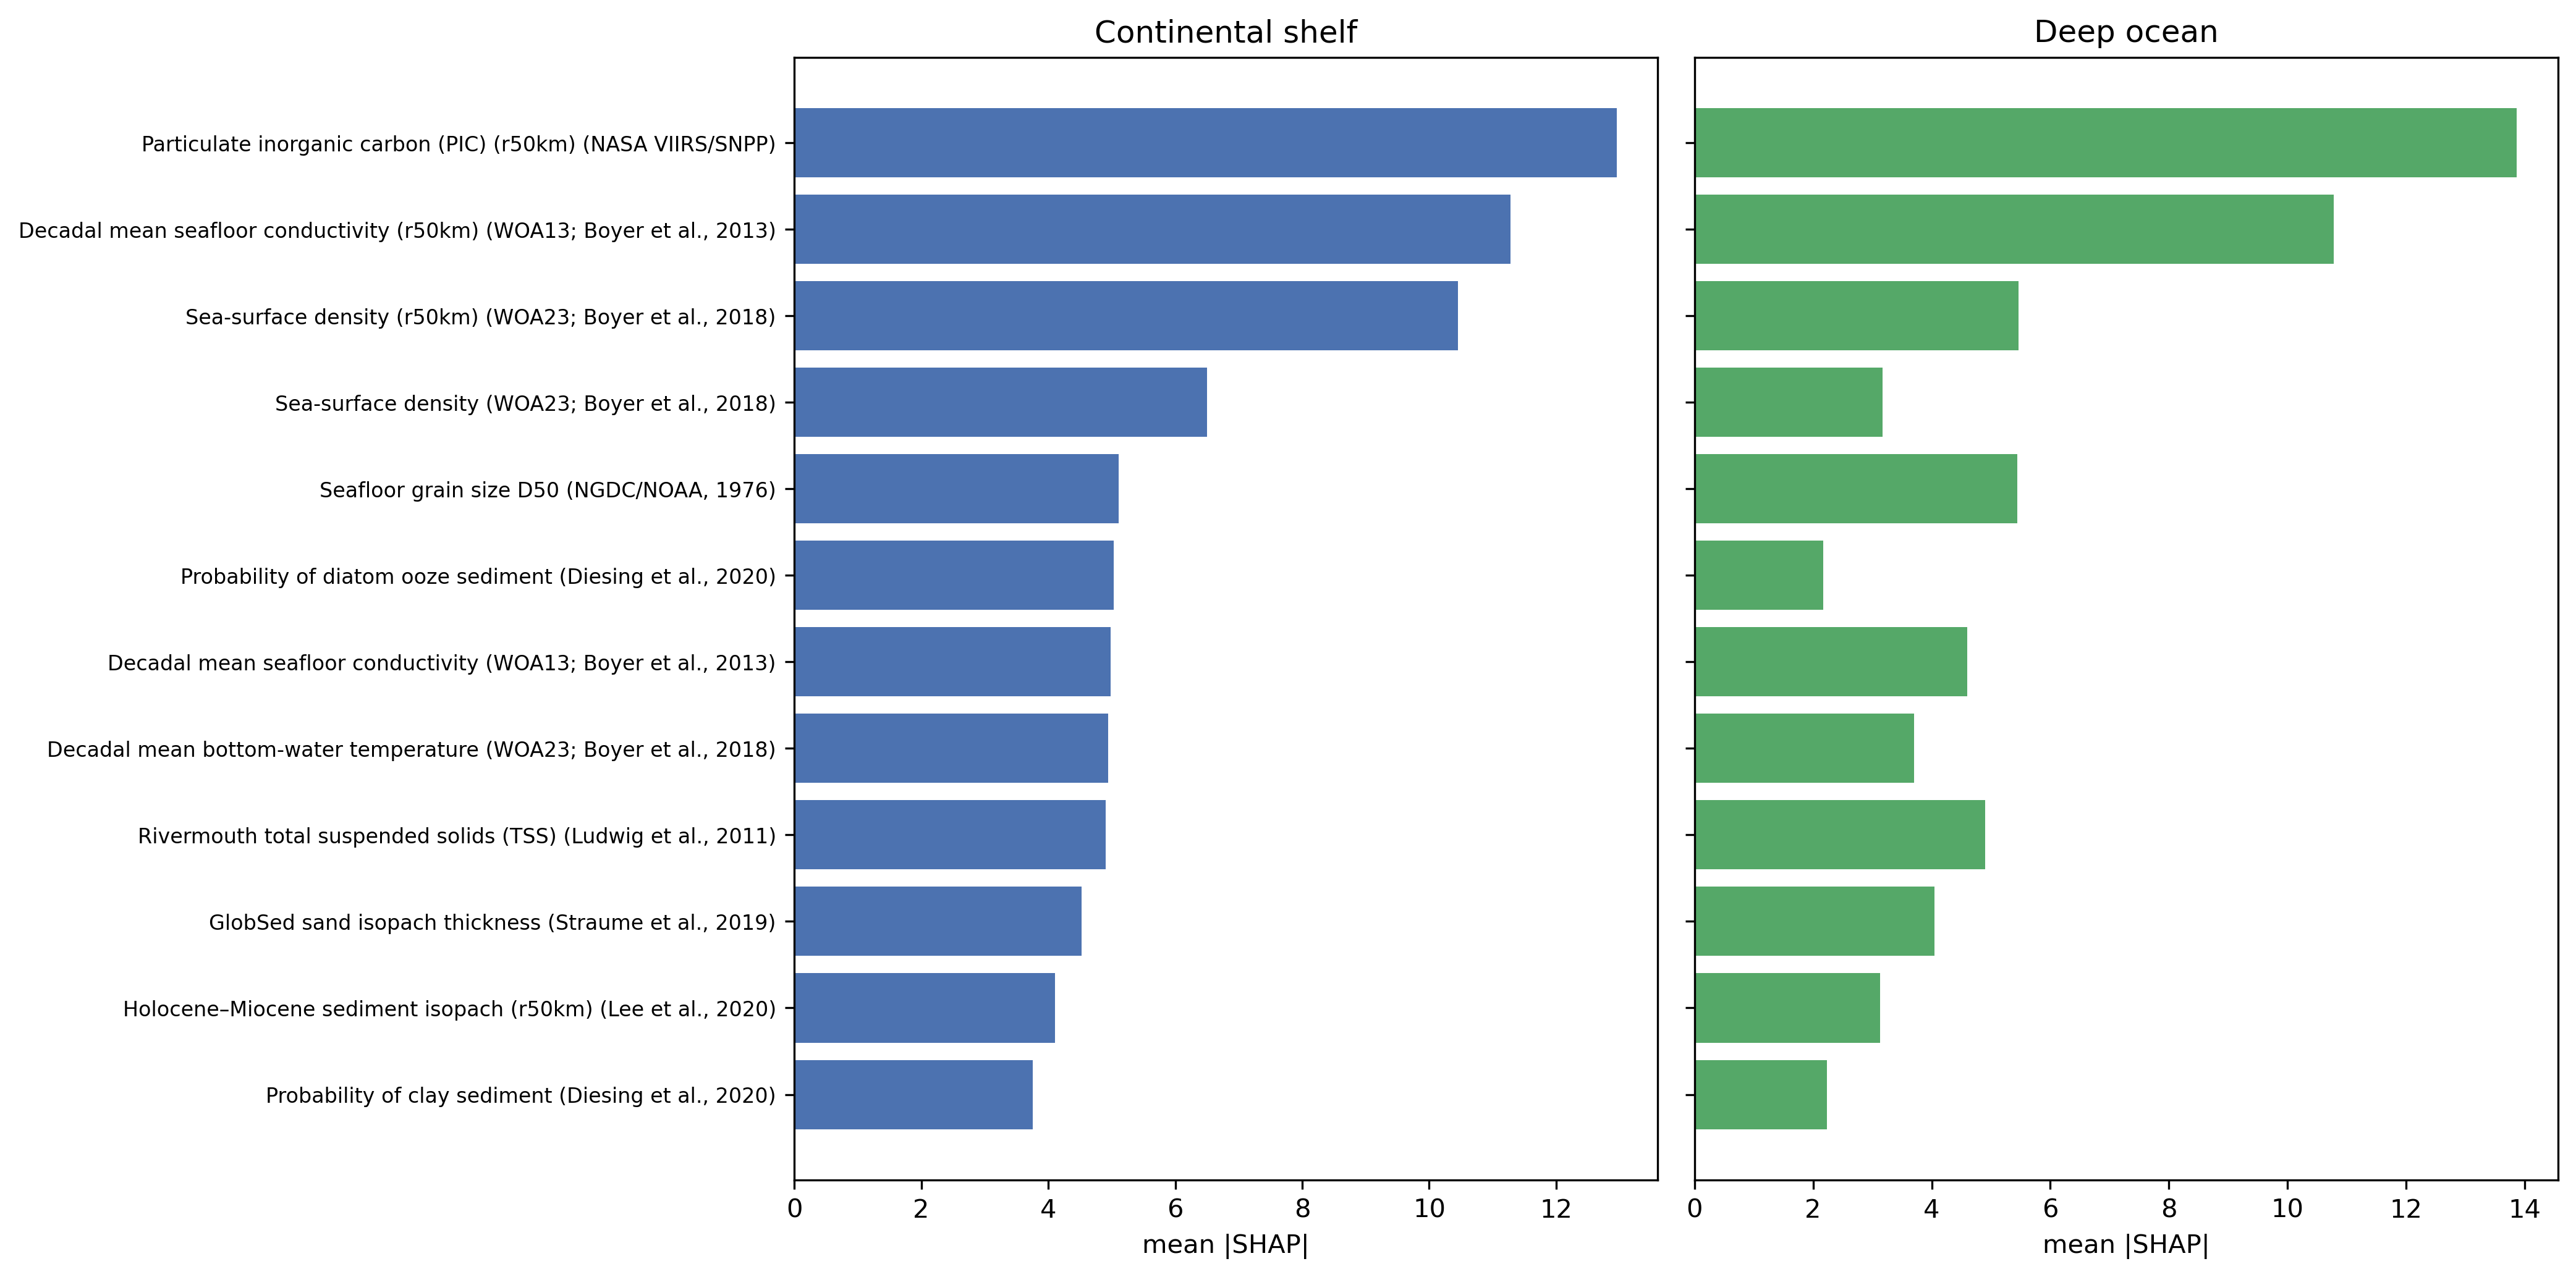

In [2]:
# Optional live run (GPU). Prefer the sbatch file for production jobs.
if RUN_SHAP:
    cmd = [
        str(py),
        "Sed_MTL_shap_nomask_map47.py",
        "--domain", "world",
        "--batch-size", "256",
        "--plot-samples", "5000",
        "--background-samples", "100",
    ]
    if SKIP_TRAIN:
        cmd.append("--skip-train")
    print("Running:", " ".join(cmd))
    env = os.environ.copy()
    env["MASKED_FEATURE_VARIANT"] = "values_only"
    env["PYTHONUNBUFFERED"] = "1"
    subprocess.check_call(cmd, cwd=str(nn4_nb), env=env)
else:
    print("Using archived map-47 SHAP results (RUN_SHAP=False).")
    print("Figures: docs/figs/shap_values_*_new.png, shap_ranking_predictors_map47.png")


## Information gain (KL map from MC dropout)

An ensemble of stochastic forward passes (MC dropout, $n_{MC}=50$) yields a
predictive distribution of MAR at each grid cell. Comparing that distribution to
a reference gives a **Kullback–Leibler information-gain** map: high values mark
regions where additional observations would most reduce uncertainty.

Companion maps show ensemble spread (uncertainty) and overconfident cells.

> Outputs are from job `MTL_infogain_nomask_map47_24085833` / SI figures in `docs/figs/`.


Using archived map-47 information-gain results (RUN_INFOGAIN=False).
Figures: docs/figs/infogain.png, mc_dropout_uncertainty.png, overconfidence_map.png

Early stopping at epoch 401 to avoid overfitting.
Saved checkpoint: /gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/models/MTL_single_nomask_map47_[128,128,128,128]_shared2.pt
MAR test MAE=19.6755  RMSE=85.9032  R2=0.8138  corr=0.9027
Building MC-dropout ensemble: n_mc=50, grid=2160x4320, batch=8192
  writing /gxfs_work/cau/sunms498/work/nn4sedratetoc/results/infogain_MTL_single_nomask_map47_[128,128,128,128]_shared2/prediction_map_dist_MAR.npy
Orienting ensemble (rot90 x2 + fliplr)...
Ensemble ready: /gxfs_work/cau/sunms498/work/nn4sedratetoc/results/infogain_MTL_single_nomask_map47_[128,128,128,128]_shared2/prediction_map_dist_MAR.npy
Loading ensemble for KL map...
Writing /gxfs_work/cau/sunms498/work/nn4sedratetoc/results/infogain_MTL_single_nomask_map47_[128,128,128,128]_shared2/infogain.png
Writing /gxfs_work/cau/sunms498/

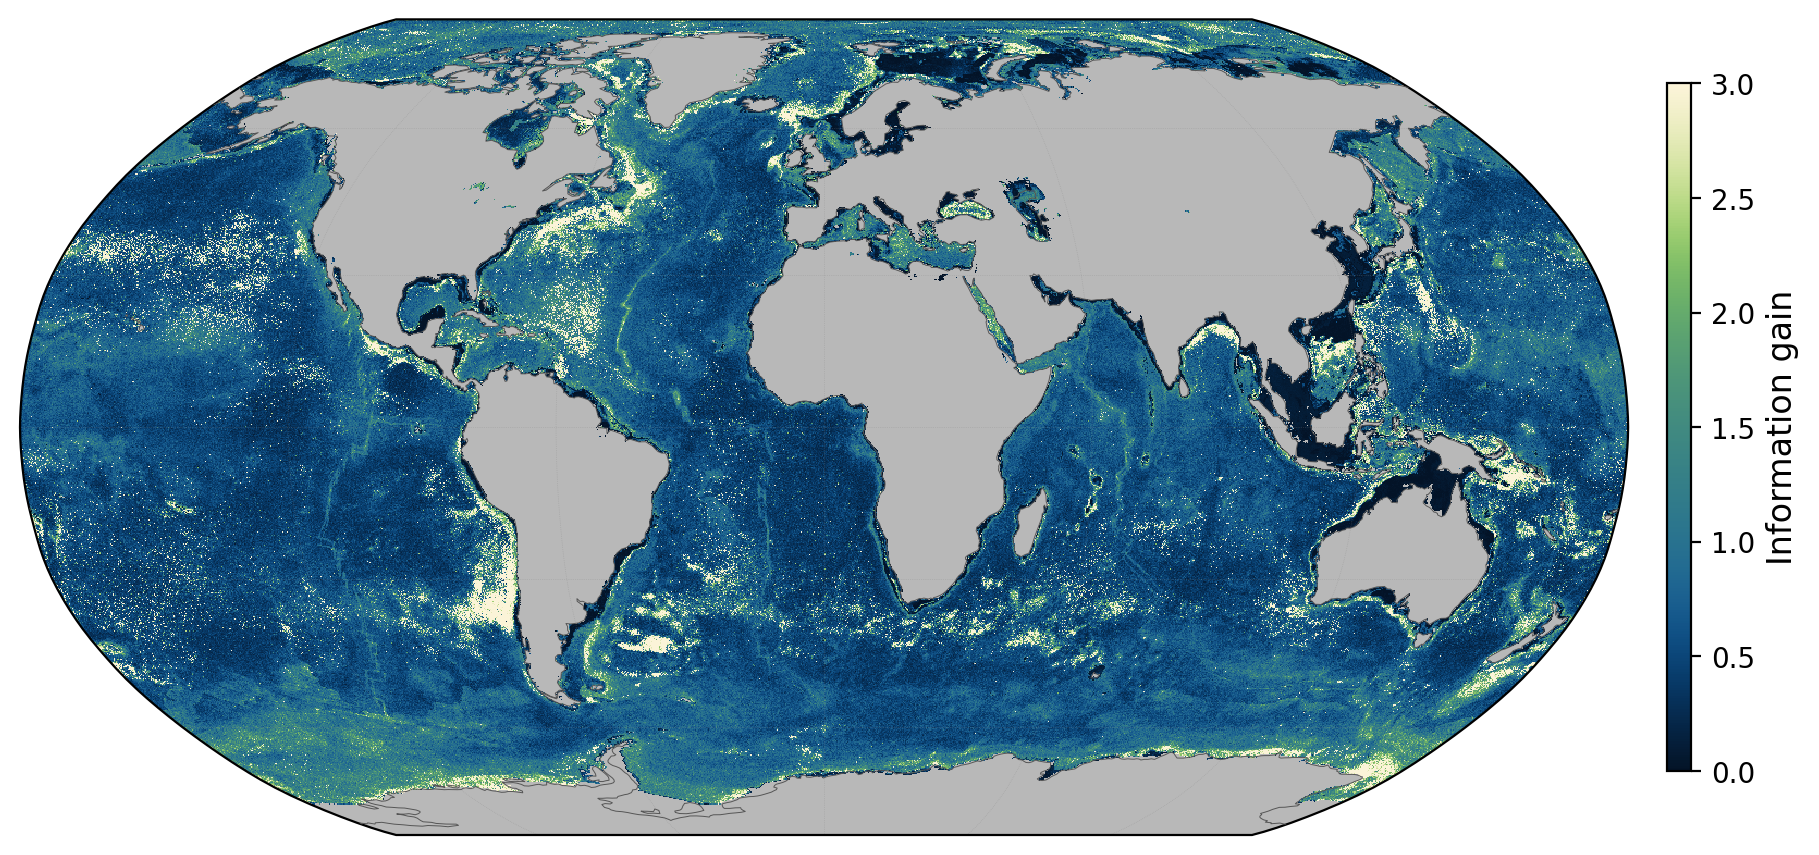

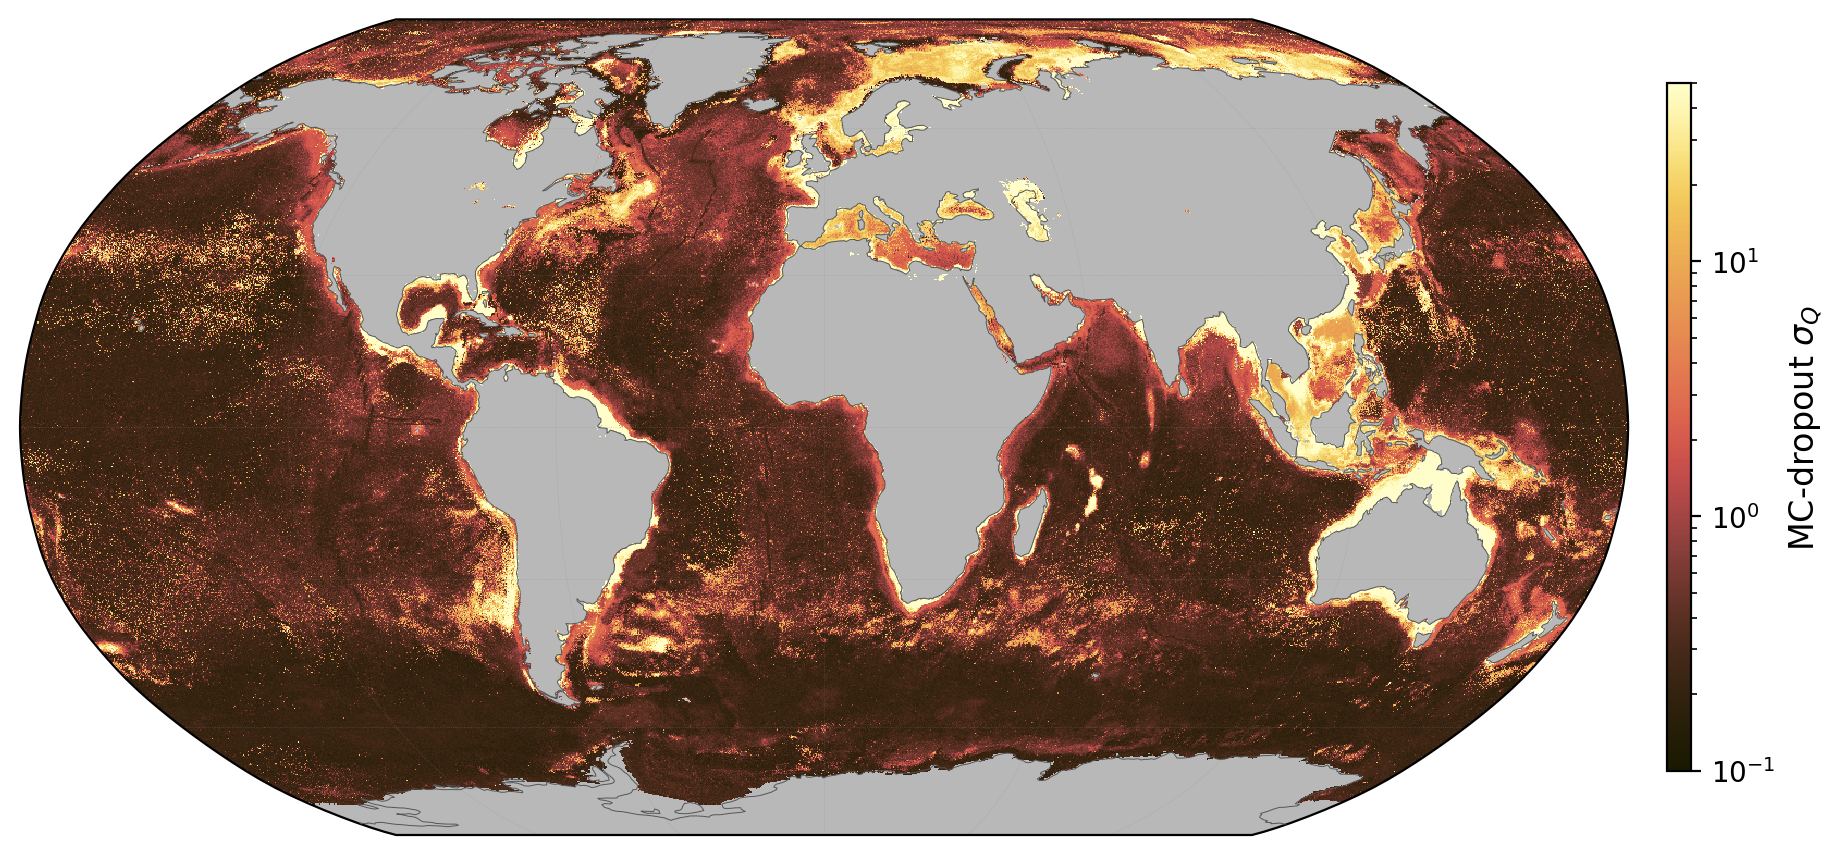

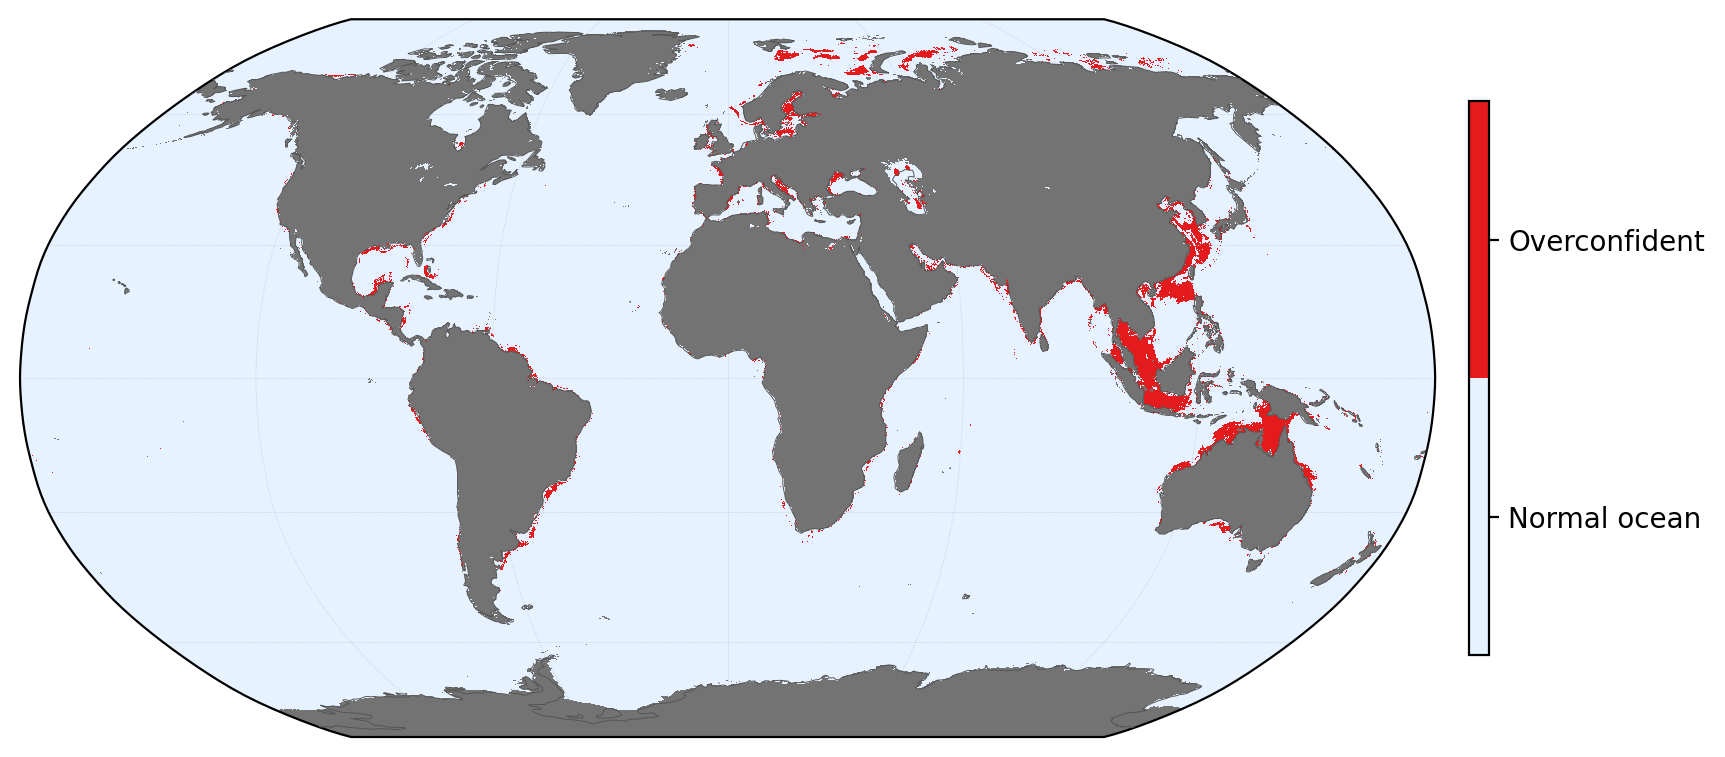

In [3]:
# Optional live run (GPU). Prefer the sbatch file for production jobs.
if RUN_INFOGAIN:
    cmd = [str(py), "Sed_MTL_infogain_nomask_map47.py"]
    if SKIP_TRAIN:
        cmd.append("--skip-train")
    print("Running:", " ".join(cmd))
    env = os.environ.copy()
    env["MASKED_FEATURE_VARIANT"] = "values_only"
    env["PYTHONUNBUFFERED"] = "1"
    subprocess.check_call(cmd, cwd=str(nn4_nb), env=env)
else:
    print("Using archived map-47 information-gain results (RUN_INFOGAIN=False).")
    print("Figures: docs/figs/infogain.png, mc_dropout_uncertainty.png, overconfidence_map.png")


## Where outputs land

| Product | Path |
|---------|------|
| SHAP rankings / beeswarms (world) | `nn4sedratetoc/results/shap_MTL_single_nomask_map47_[128,128,128,128]_shared2_world/` |
| Information-gain maps | `nn4sedratetoc/results/infogain_MTL_single_nomask_map47_[128,128,128,128]_shared2/` |
| SI copies used above | `nn4sedratetoc/docs/figs/shap_*.png`, `infogain.png`, … |
| MTL training notebook | `notebooks_2/train_multi_task_learning.ipynb` |

The older exploratory notebooks `explain_multi_task_learning*.ipynb` and
`InfoGain.ipynb` retain prior interactive analyses; **map-47 paper figures** for
the selected MTL are the ones embedded here.
